In [ ]:
from sklearn.datasets import load_digits

# Load dataset
digits = load_digits()

# Identify components
print(f"Feature Variables (Pixels): {digits.feature_names[:5]}... (Total {len(digits.feature_names)})")
print(f"Target Variable: target (Digit 0-9)")
print(f"Number of Classes: {len(digits.target_names)} ({digits.target_names})")
print(f"Dataset Size: {digits.data.shape[0]} samples")
print(f"Image Shape: {digits.images[0].shape}")

Feature Variables (Pixels): ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4']... (Total 64)
Target Variable: target (Digit 0-9)
Number of Classes: 10 ([0 1 2 3 4 5 6 7 8 9])
Dataset Size: 1797 samples
Image Shape: (8, 8)


In [ ]:
import pandas as pd

# Create DataFrame from flattened pixel data
df = pd.DataFrame(digits.data, columns=[f"pixel_{i}" for i in range(digits.data.shape[1])])
df['target'] = digits.target
df['digit_name'] = df['target'].astype(str)

# Display sample
display(df.head())

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target,digit_name
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4,4


In [ ]:
# Check for missing values
print("Any missing values?", df.isnull().values.any())

# Check class distribution
print("\nSamples per Digit:")
print(df['target'].value_counts().sort_index())

Any missing values? False

Samples per Digit:
target
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X = digits.data
y = digits.target

# 60% Train, 40% Temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# 20% Val, 20% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")

Training set: 1078 samples
Validation set: 359 samples
Testing set: 360 samples


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# 1. Raw Model
model_raw = LogisticRegression(max_iter=10000)
model_raw.fit(X_train, y_train)
raw_acc = accuracy_score(y_val, model_raw.predict(X_val))

# 2. Scaled Model
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

model_scaled = LogisticRegression(max_iter=10000)
model_scaled.fit(X_train_scaled, y_train)
scaled_acc = accuracy_score(y_val, model_scaled.predict(X_val_scaled))

print(f"Raw Accuracy: {raw_acc:.4f}")
print(f"Scaled Accuracy: {scaled_acc:.4f}")
# Discussion: Scaling prevents pixels with higher variance from dominating
# the weight updates during training.

Raw Accuracy: 0.9526
Scaled Accuracy: 0.9666


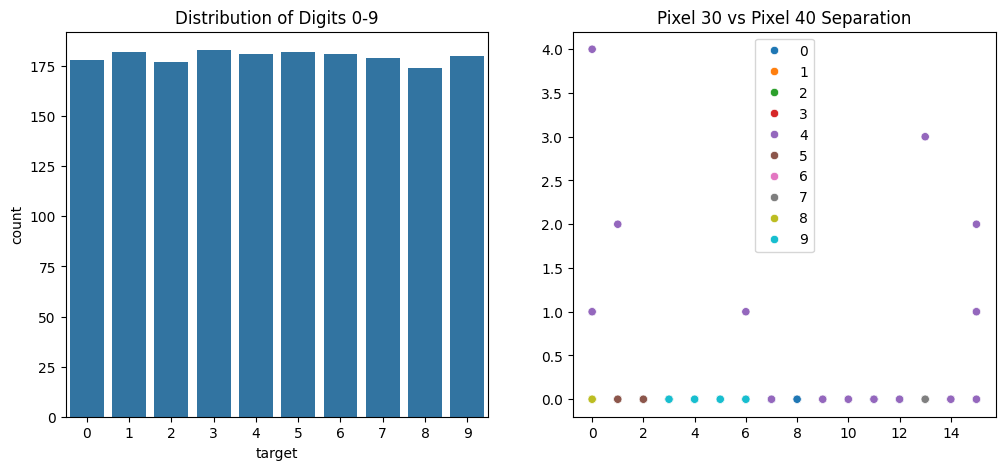

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

# Plot 1: Class Distribution
plt.subplot(1, 2, 1)
sns.countplot(x=df['target'])
plt.title("Distribution of Digits 0-9")

# Plot 2: Pixel 30 vs Pixel 40 (Arbitrary features to show separation)
plt.subplot(1, 2, 2)
sns.scatterplot(x=X[:, 30], y=X[:, 40], hue=y, palette='tab10', legend='full')
plt.title("Pixel 30 vs Pixel 40 Separation")
plt.show()

# Explanation: The scatter plot shows significant overlap, suggesting that
# two pixels alone aren't enough to identify a digit; we need the full 64-pixel context.

In [ ]:
# Using only two pixels for training
X_train_reduced = X_train_scaled[:, [30, 40]]
X_val_reduced = X_val_scaled[:, [30, 40]]

model_reduced = LogisticRegression()
model_reduced.fit(X_train_reduced, y_train)
reduced_acc = accuracy_score(y_val, model_reduced.predict(X_val_reduced))

print(f"Full Feature (64) Accuracy: {scaled_acc:.4f}")
print(f"Reduced Feature (2) Accuracy: {reduced_acc:.4f}")

Full Feature (64) Accuracy: 0.9666
Reduced Feature (2) Accuracy: 0.1978


In [ ]:
# Change random_state to 7
X_train_rs, X_test_rs, y_train_rs, y_test_rs = train_test_split(
    X, y, test_size=0.2, random_state=7, stratify=y
)

model_rs = LogisticRegression(max_iter=10000)
model_rs.fit(X_train_rs, y_train_rs)
rs_acc = accuracy_score(y_test_rs, model_rs.predict(X_test_rs))

print(f"Original Seed Accuracy: {scaled_acc:.4f}")
print(f"New Seed Accuracy: {rs_acc:.4f}")

Original Seed Accuracy: 0.9666
New Seed Accuracy: 0.9694


In [ ]:
X_test_scaled = scaler.transform(X_test)
y_pred = model_scaled.predict(X_test_scaled)
y_proba = model_scaled.predict_proba(X_test_scaled)

# Analysis for the first test sample
print(f"True Label: {y_test[0]}")
print(f"Predicted Label: {y_pred[0]}")
print("\nProbabilities for each class (0-9):")
for i, prob in enumerate(y_proba[0]):
    print(f"Digit {i}: {prob:.4f}")

# Explanation: The class with the highest probability is selected.
# Probabilities allow us to see if the model was "confused" between similar digits like 1 and 7.

True Label: 9
Predicted Label: 9

Probabilities for each class (0-9):
Digit 0: 0.0004
Digit 1: 0.0058
Digit 2: 0.0000
Digit 3: 0.0010
Digit 4: 0.0000
Digit 5: 0.0000
Digit 6: 0.0000
Digit 7: 0.0781
Digit 8: 0.0000
Digit 9: 0.9146
